# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [ ]:
# Replace None with your code
# Imports
None

# Create connection to database
None

In [3]:
# Imports
import sqlite3
import pandas as pd

# Create connection to database
conn = sqlite3.connect('data.sqlite')

### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [5]:
california_customers = pd.read_sql_query("""
    SELECT
        customerNumber,
        customerName,
        city,
        state,
        country,
        creditLimit
    FROM customers
    WHERE country = 'USA'
      AND state = 'CA'
      AND CAST(creditLimit AS REAL) > 25000
""", conn)

california_customers

,customerNumber,customerName,city,state,country,creditLimit
0,124,Mini Gifts Distributors Ltd.,San Rafael,CA,USA,210500.00
1,129,Mini Wheels Co.,San Francisco,CA,USA,64600.00
2,161,Technics Stores Inc.,Burlingame,CA,USA,84600.00
3,205,Toys4GrownUps.com,Pasadena,CA,USA,90700.00
4,239,Collectable Mini Designs Co.,San Diego,CA,USA,105000.00
5,321,Corporate Gift Ideas Co.,San Francisco,CA,USA,105000.00
6,347,"Men 'R' US Retailers, Ltd.",Los Angeles,CA,USA,57700.00
7,450,The Sharp Gifts Warehouse,San Jose,CA,USA,77600.00
8,475,West Coast Collectables Co.,Burbank,CA,USA,55400.00
9,487,Signal Collectibles Ltd.,Brisbane,CA,USA,60300.00


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [6]:
# Replace None with your code
# Query international customers with "Collect" in their name

international_collectable_customers = pd.read_sql_query("""
    SELECT
        customerNumber,
        customerName,
        city,
        country,
        creditLimit
    FROM customers
    WHERE country != 'USA'
      AND customerName LIKE '%Collect%'
""", conn)

international_collectable_customers

,customerNumber,customerName,city,country,creditLimit
0,114,"Australian Collectors, Co.",Melbourne,Australia,117300.00
1,189,"Clover Collections, Co.",Dublin,Ireland,69400.00
2,201,"UK Collectables, Ltd.",Liverpool,UK,92700.00
3,211,"King Kong Collectables, Co.",Central Hong Kong,Hong Kong,58600.00
4,227,Heintze Collectables,Århus,Denmark,120800.00
5,260,"Royal Canadian Collectables, Ltd.",Tsawassen,Canada,89600.00
6,293,BG&E Collectables,Fribourg,Switzerland,0.00
7,353,Reims Collectables,Reims,France,81100.00
8,376,Precious Collectables,Bern,Switzerland,0.00
9,382,Salzburg Collectables,Salzburg,Austria,71700.00


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

## Type your answer in markdown here!

The SQL query does not use a `WHERE` clause because the analysis is intended to include all product lines with recorded orders.

Instead, I used an `INNER JOIN` to connect the products table with the orderdetails table using the productCode. This ensures that the analysis includes products that have been ordered and have corresponding order details.

I also used `GROUP BY` to organize the information by product line, `COUNT(DISTINCT productCode)` to count each unique product only once, and `SUM(quantityOrdered)` to calculate the total quantity ordered for each product line.

This approach ensures that the results provide a comprehensive comparison of product variety and customer demand across the product lines.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [7]:
# Replace None with your code
# Average credit limit of customers in each USA state

usa_state_credit = pd.read_sql_query("""
    SELECT
        state,
        COUNT(customerNumber) AS customer_count,
        AVG(CAST(creditLimit AS REAL)) AS average_credit_limit
    FROM customers
    WHERE country = 'USA'
      AND state IS NOT NULL
      AND creditLimit IS NOT NULL
    GROUP BY state
    ORDER BY average_credit_limit DESC
""", conn)

usa_state_credit

,state,customer_count,average_credit_limit
0,NH,1,114200.000000
1,NY,6,89966.666667
2,PA,3,84766.666667
3,CA,11,83854.545455
4,NV,1,71800.000000
5,MA,9,70755.555556
6,CT,4,57350.000000
7,NJ,1,43000.000000


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

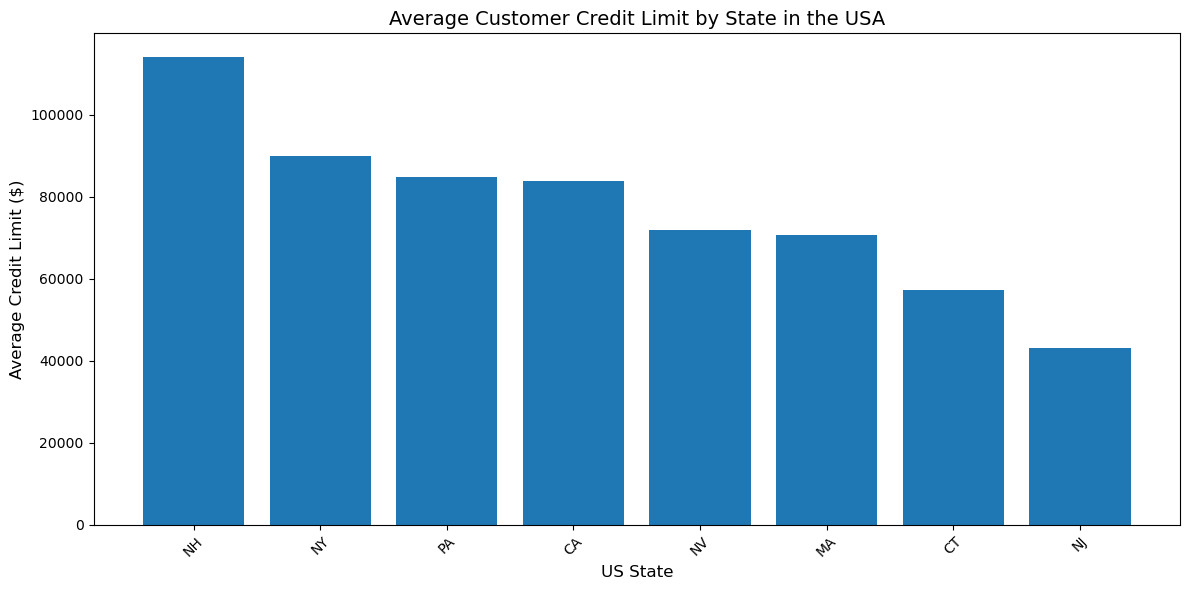

In [8]:
# Replace None with your visual code
# Produce a visual to represent the average credit limit by state
import matplotlib.pyplot as plt

# Create bar chart
plt.figure(figsize=(12, 6))

plt.bar(
    usa_state_credit['state'],
    usa_state_credit['average_credit_limit']
)

# Add chart title and labels
plt.title('Average Customer Credit Limit by State in the USA',
          fontsize=14)

plt.xlabel('US State', fontsize=12)
plt.ylabel('Average Credit Limit ($)', fontsize=12)

# Rotate state labels for readability
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [9]:
# Replace None with your code
# Query the top 10 customers based on total payments

top_customers = pd.read_sql_query("""
    SELECT
        customers.customerNumber,
        customers.customerName,
        SUM(payments.amount) AS total_payments
    FROM customers
    JOIN payments
        ON customers.customerNumber = payments.customerNumber
    GROUP BY
        customers.customerNumber,
        customers.customerName
    ORDER BY total_payments DESC
    LIMIT 10
""", conn)

top_customers

,customerNumber,customerName,total_payments
0,141,Euro+ Shopping Channel,715738.98
1,124,Mini Gifts Distributors Ltd.,584188.24
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,148,"Dragon Souveniers, Ltd.",156251.03
5,323,"Down Under Souveniers, Inc",154622.08
6,187,"AV Stores, Co.",148410.09
7,276,"Anna's Decorations, Ltd",137034.22
8,321,Corporate Gift Ideas Co.,132340.78
9,146,"Saveley & Henriot, Co.",130305.35


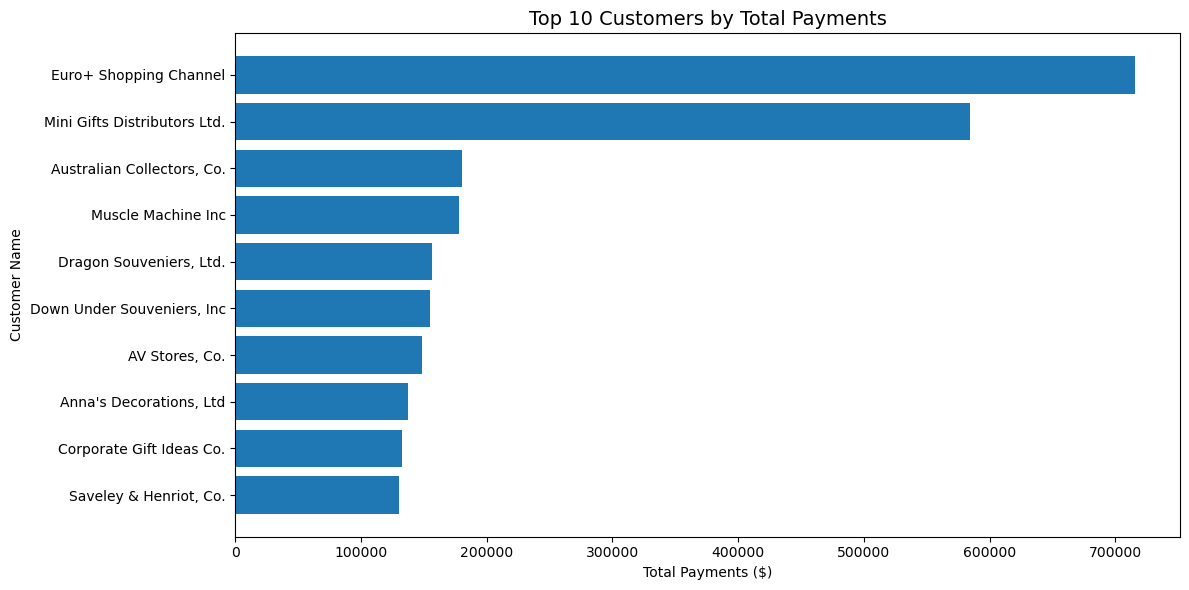

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.barh(
    top_customers['customerName'],
    top_customers['total_payments']
)

plt.title('Top 10 Customers by Total Payments',
          fontsize=14)

plt.xlabel('Total Payments ($)')
plt.ylabel('Customer Name')

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

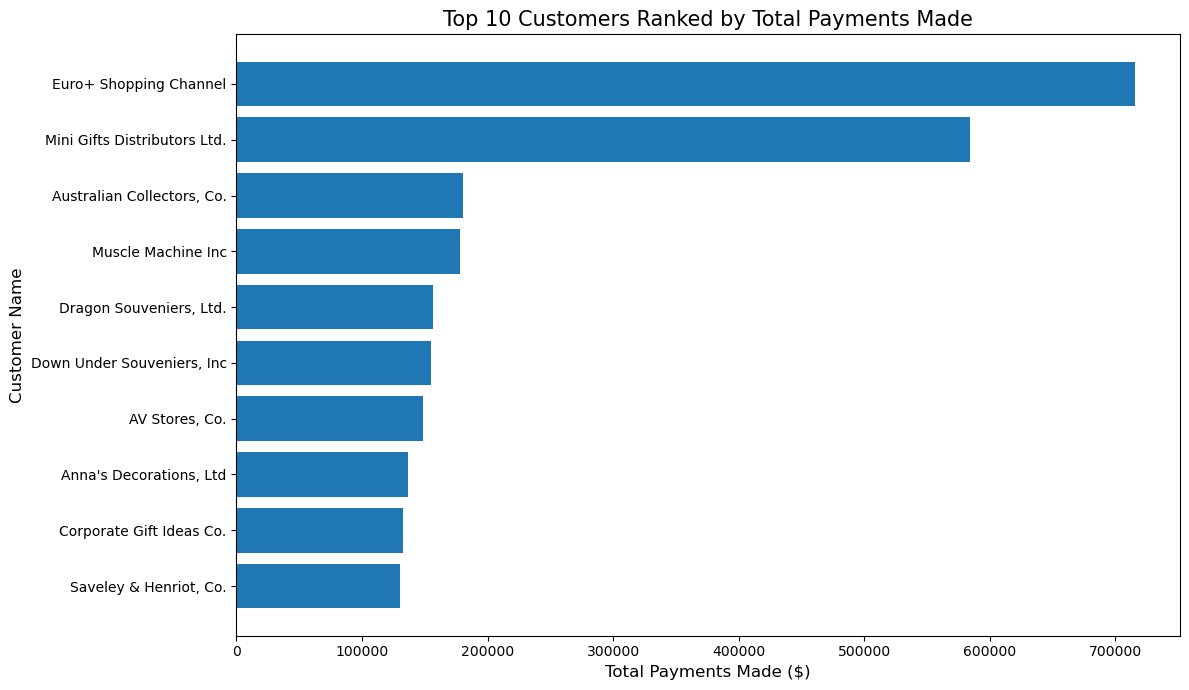

In [11]:
# Replace None with your visual code
# Produce a visual to represent the top ten customers in terms of total payments
# Produce a visual to represent the top ten customers in terms of total payments

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.barh(
    top_customers['customerName'],
    top_customers['total_payments']
)

plt.title('Top 10 Customers Ranked by Total Payments Made',
          fontsize=15)

plt.xlabel('Total Payments Made ($)', fontsize=12)
plt.ylabel('Customer Name', fontsize=12)

# Display the highest-paying customer at the top
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [12]:
# Query customers and products purchased in quantities of 10 or more

customer_product_quantities = pd.read_sql_query("""
    SELECT
        customers.customerNumber,
        customers.customerName,
        products.productCode,
        products.productName,
        SUM(orderdetails.quantityOrdered) AS total_quantity
    FROM customers
    JOIN orders
        ON customers.customerNumber = orders.customerNumber
    JOIN orderdetails
        ON orders.orderNumber = orderdetails.orderNumber
    JOIN products
        ON orderdetails.productCode = products.productCode
    GROUP BY
        customers.customerNumber,
        customers.customerName,
        products.productCode,
        products.productName
    HAVING SUM(orderdetails.quantityOrdered) >= 10
    ORDER BY total_quantity ASC
""", conn)

customer_product_quantities

,customerNumber,customerName,productCode,productName,total_quantity
0,314,Petit Auto,S18_2949,1913 Ford Model T Speedster,10
1,412,"Extreme Desk Decorations, Ltd",S24_4620,1961 Chevrolet Impala,10
2,119,La Rochelle Gifts,S32_2509,1954 Greyhound Scenicruiser,11
3,328,Tekni Collectables Inc.,S700_1691,American Airlines: B767-300,11
4,450,The Sharp Gifts Warehouse,S24_3191,1969 Chevrolet Camaro Z28,13
...,...,...,...,...,...
2526,141,Euro+ Shopping Channel,S24_3432,2002 Chevy Corvette,174
2527,141,Euro+ Shopping Channel,S12_4473,1957 Chevy Pickup,183
2528,141,Euro+ Shopping Channel,S24_1444,1970 Dodge Coronet,197
2529,141,Euro+ Shopping Channel,S24_2840,1958 Chevy Corvette Limited Edition,245


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [13]:
# Query product lines, number of products and total quantity ordered

product_line_analysis = pd.read_sql_query("""
    SELECT
        products.productLine,
        COUNT(DISTINCT products.productCode) AS total_products,
        SUM(orderdetails.quantityOrdered) AS total_quantity_ordered
    FROM products
    JOIN orderdetails
        ON products.productCode = orderdetails.productCode
    GROUP BY products.productLine
    ORDER BY total_quantity_ordered DESC
""", conn)

product_line_analysis

,productLine,total_products,total_quantity_ordered
0,Classic Cars,37,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

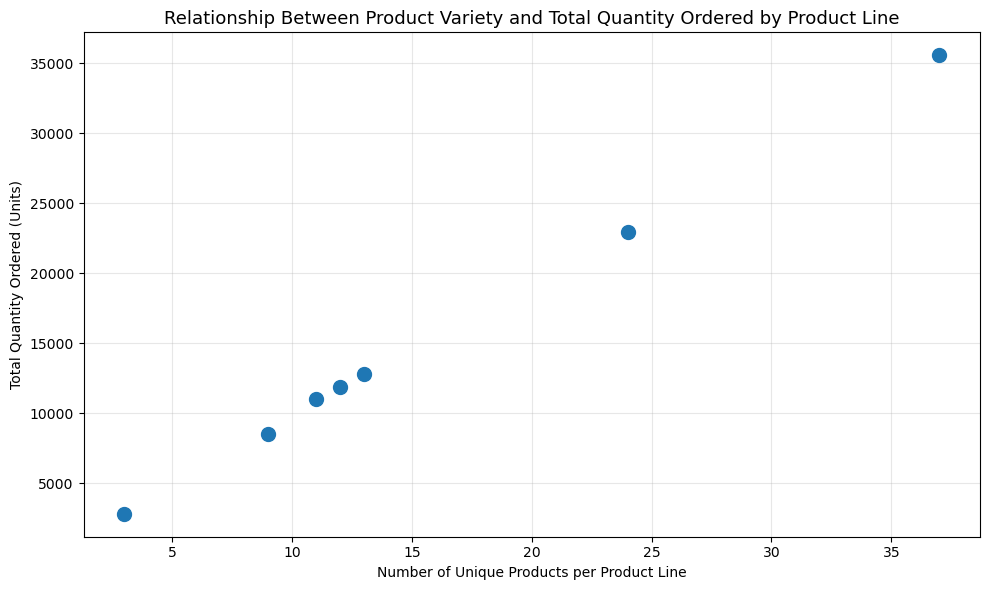

In [14]:
# Replace None with your visual code
# Produce a visual to represent the the relation between number of products and the total amount ordered
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    product_line_analysis['total_products'],
    product_line_analysis['total_quantity_ordered'],
    s=100
)

plt.title(
    'Relationship Between Product Variety and Total Quantity Ordered by Product Line',
    fontsize=13
)

plt.xlabel('Number of Unique Products per Product Line')
plt.ylabel('Total Quantity Ordered (Units)')

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

## Type your answer in markdown here!

The SQL query does not use a `WHERE` clause because the analysis is intended to include all product lines with recorded orders.

Instead, I used an `INNER JOIN` to connect the products table with the orderdetails table using the productCode. This ensures that the analysis includes products that have been ordered and have corresponding order details.

I also used `GROUP BY` to organize the information by product line, `COUNT(DISTINCT productCode)` to count each unique product only once, and `SUM(quantityOrdered)` to calculate the total quantity ordered for each product line.

This approach ensures that the results provide a comprehensive comparison of product variety and customer demand across the product lines.

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [15]:
# Replace None with your code# Query employees working in offices with fewer than 5 employees

remote_office_employees = pd.read_sql_query("""
    SELECT
        e.employeeNumber,
        e.firstName,
        e.lastName,
        e.jobTitle,
        o.officeCode,
        o.city,
        o.country,
        m.firstName AS supervisor_first_name,
        m.lastName AS supervisor_last_name
    FROM employees AS e
    JOIN offices AS o
        ON e.officeCode = o.officeCode
    LEFT JOIN employees AS m
        ON e.reportsTo = m.employeeNumber
    WHERE e.officeCode IN (
        SELECT officeCode
        FROM employees
        GROUP BY officeCode
        HAVING COUNT(employeeNumber) < 5
    )
    ORDER BY o.city, e.lastName
""", conn)

remote_office_employees

,employeeNumber,firstName,lastName,jobTitle,officeCode,city,country,supervisor_first_name,supervisor_last_name
0,1188,Julie,Firrelli,Sales Rep,2,Boston,USA,Anthony,Bow
1,1216,Steve,Patterson,Sales Rep,2,Boston,USA,Anthony,Bow
2,1501,Larry,Bott,Sales Rep,7,London,UK,Gerard,Bondur
3,1504,Barry,Jones,Sales Rep,7,London,UK,Gerard,Bondur
4,1286,Foon Yue,Tseng,Sales Rep,3,NYC,USA,Anthony,Bow
5,1323,George,Vanauf,Sales Rep,3,NYC,USA,Anthony,Bow
6,1611,Andy,Fixter,Sales Rep,6,Sydney,Australia,William,Patterson
7,1619,Tom,King,Sales Rep,6,Sydney,Australia,William,Patterson
8,1612,Peter,Marsh,Sales Rep,6,Sydney,Australia,William,Patterson
9,1088,William,Patterson,Sales Manager (APAC),6,Sydney,Australia,Mary,Patterson


In [16]:
remote_office_employees = pd.read_sql_query("""
SELECT
    e.employeeNumber,
    e.firstName,
    e.lastName,
    e.jobTitle,
    e.officeCode,
    o.city,
    o.country,
    e.reportsTo,
    m.firstName AS supervisor_first_name,
    m.lastName AS supervisor_last_name
FROM employees e
JOIN offices o
    ON e.officeCode = o.officeCode
LEFT JOIN employees m
    ON e.reportsTo = m.employeeNumber
WHERE e.officeCode IN (
    SELECT officeCode
    FROM employees
    GROUP BY officeCode
    HAVING COUNT(*) < 5
)
ORDER BY o.city, e.lastName
""", conn)

remote_office_employees

,employeeNumber,firstName,lastName,jobTitle,officeCode,city,country,reportsTo,supervisor_first_name,supervisor_last_name
0,1188,Julie,Firrelli,Sales Rep,2,Boston,USA,1143,Anthony,Bow
1,1216,Steve,Patterson,Sales Rep,2,Boston,USA,1143,Anthony,Bow
2,1501,Larry,Bott,Sales Rep,7,London,UK,1102,Gerard,Bondur
3,1504,Barry,Jones,Sales Rep,7,London,UK,1102,Gerard,Bondur
4,1286,Foon Yue,Tseng,Sales Rep,3,NYC,USA,1143,Anthony,Bow
5,1323,George,Vanauf,Sales Rep,3,NYC,USA,1143,Anthony,Bow
6,1611,Andy,Fixter,Sales Rep,6,Sydney,Australia,1088,William,Patterson
7,1619,Tom,King,Sales Rep,6,Sydney,Australia,1088,William,Patterson
8,1612,Peter,Marsh,Sales Rep,6,Sydney,Australia,1088,William,Patterson
9,1088,William,Patterson,Sales Manager (APAC),6,Sydney,Australia,1056,Mary,Patterson


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

## Type your answer in markdown here!

I decided to use a subquery because I first needed to identify which offices had fewer than five employees before retrieving the individual employee details.

The subquery groups employees by their officeCode using `GROUP BY` and then uses `HAVING COUNT(*) < 5` to identify offices with fewer than five employees.

The main query uses the `IN` operator to compare each employee's officeCode against the office codes returned by the subquery. This ensures that only employees working in the identified offices are selected.

I then used JOIN to connect the employees table with the offices table to retrieve office locations. I also used a LEFT JOIN on the employees table to retrieve supervisor names using the `reportsTo` and `employeeNumber` columns.

This approach allows the query to identify smaller offices and return all the relevant employee, job title, office location, and supervisor information needed by management to plan remote and hybrid working arrangements.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [17]:
# Close connection to database
conn.close()

In [18]:
conn = sqlite3.connect('data.sqlite')

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [3]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

In [19]:
# Begin your code here

# Import libraries
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile

# Extract database if it has not already been extracted
import os

if not os.path.exists('im.db'):
    with zipfile.ZipFile('im.db.zip', 'r') as zip_ref:
        zip_ref.extractall('./')

# Establish database connection
conn4 = sqlite3.connect('im.db')

print("Database connected successfully!")


Database connected successfully!


In [20]:

# Retrieve all database tables
tables = pd.read_sql_query("""
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
""", conn4)

tables


,name
0,movie_basics
1,directors
2,known_for
3,movie_akas
4,movie_ratings
5,persons
6,principals
7,writers


In [21]:

# View the database schema
schema_df = pd.read_sql_query("""
    SELECT *
    FROM sqlite_master
    WHERE type = 'table'
""", conn4)

schema_df


,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


In [22]:

# Inspect movie_basics columns
movie_columns = pd.read_sql_query("""
    PRAGMA table_info(movie_basics)
""", conn4)

movie_columns


,cid,name,type,notnull,dflt_value,pk
0,0,movie_id,TEXT,0,None,0
1,1,primary_title,TEXT,0,None,0
2,2,original_title,TEXT,0,None,0
3,3,start_year,INTEGER,0,None,0
4,4,runtime_minutes,REAL,0,None,0
5,5,genres,TEXT,0,None,0


In [23]:

# Inspect movie_ratings columns
rating_columns = pd.read_sql_query("""
    PRAGMA table_info(movie_ratings)
""", conn4)

rating_columns


,cid,name,type,notnull,dflt_value,pk
0,0,movie_id,TEXT,0,None,0
1,1,averagerating,REAL,0,None,0
2,2,numvotes,INTEGER,0,None,0


In [24]:

# Count the total number of movies
total_movies = pd.read_sql_query("""
    SELECT COUNT(*) AS total_movies
    FROM movie_basics
""", conn4)

total_movies


,total_movies
0,146144


In [25]:

# Examine the movie release period
release_years = pd.read_sql_query("""
    SELECT
        MIN(start_year) AS earliest_release_year,
        MAX(start_year) AS latest_release_year,
        COUNT(*) AS total_movies
    FROM movie_basics
    WHERE CAST(start_year AS INTEGER) BETWEEN 2010 AND 2019
""", conn4)

release_years


,earliest_release_year,latest_release_year,total_movies
0,2010,2019,145081


In [26]:

# Display sample movie records
sample_movies = pd.read_sql_query("""
    SELECT
        movie_id,
        primary_title,
        original_title,
        start_year,
        runtime_minutes,
        genres
    FROM movie_basics
    WHERE start_year BETWEEN 2010 AND 2019
    LIMIT 10
""", conn4)

sample_movies


,movie_id,primary_title,original_title,start_year,runtime_minutes,genres
0,tt0063540,Sunghursh,Sunghursh,2013,175.0,"Action,Crime,Drama"
1,tt0066787,One Day Before the Rainy Season,Ashad Ka Ek Din,2019,114.0,"Biography,Drama"
2,tt0069049,The Other Side of the Wind,The Other Side of the Wind,2018,122.0,Drama
3,tt0069204,Sabse Bada Sukh,Sabse Bada Sukh,2018,NaN,"Comedy,Drama"
4,tt0100275,The Wandering Soap Opera,La Telenovela Errante,2017,80.0,"Comedy,Drama,Fantasy"
5,tt0111414,A Thin Life,A Thin Life,2018,75.0,Comedy
6,tt0112502,Bigfoot,Bigfoot,2017,NaN,"Horror,Thriller"
7,tt0137204,Joe Finds Grace,Joe Finds Grace,2017,83.0,"Adventure,Animation,Comedy"
8,tt0139613,O Silêncio,O Silêncio,2012,NaN,"Documentary,History"
9,tt0144449,Nema aviona za Zagreb,Nema aviona za Zagreb,2012,82.0,Biography


In [27]:

# Join movie information with ratings
movie_ratings_data = pd.read_sql_query("""
    SELECT
        mb.movie_id,
        mb.primary_title,
        mb.start_year,
        mb.runtime_minutes,
        mb.genres,
        mr.averagerating,
        mr.numvotes
    FROM movie_basics mb
    INNER JOIN movie_ratings mr
        ON mb.movie_id = mr.movie_id
    WHERE CAST(mb.start_year AS INTEGER)
        BETWEEN 2010 AND 2019
""", conn4)

movie_ratings_data.head(10)


,movie_id,primary_title,start_year,runtime_minutes,genres,averagerating,numvotes
0,tt0063540,Sunghursh,2013,175.0,"Action,Crime,Drama",7.0,77
1,tt0066787,One Day Before the Rainy Season,2019,114.0,"Biography,Drama",7.2,43
2,tt0069049,The Other Side of the Wind,2018,122.0,Drama,6.9,4517
3,tt0069204,Sabse Bada Sukh,2018,NaN,"Comedy,Drama",6.1,13
4,tt0100275,The Wandering Soap Opera,2017,80.0,"Comedy,Drama,Fantasy",6.5,119
5,tt0112502,Bigfoot,2017,NaN,"Horror,Thriller",4.1,32
6,tt0137204,Joe Finds Grace,2017,83.0,"Adventure,Animation,Comedy",8.1,263
7,tt0146592,Pál Adrienn,2010,136.0,Drama,6.8,451
8,tt0154039,So Much for Justice!,2010,100.0,History,4.6,64
9,tt0159369,Cooper and Hemingway: The True Gen,2013,180.0,Documentary,7.6,53


In [28]:

# Calculate overall movie rating statistics
rating_summary = pd.read_sql_query("""
    SELECT
        COUNT(*) AS total_rated_movies,
        ROUND(AVG(averagerating), 2) AS average_rating,
        ROUND(AVG(numvotes), 2) AS average_votes,
        MAX(averagerating) AS highest_rating,
        MIN(averagerating) AS lowest_rating
    FROM movie_ratings
    WHERE averagerating IS NOT NULL
      AND numvotes IS NOT NULL
""", conn4)

rating_summary


,total_rated_movies,average_rating,average_votes,highest_rating,lowest_rating
0,73856,6.33,3523.66,10.0,1.0


In [29]:

# Analyze movie ratings and popularity by genre

genre_ratings = pd.read_sql_query("""
    WITH RECURSIVE genre_split
        (movie_id, start_year, remaining, genre) AS (

        SELECT
            movie_id,
            start_year,
            genres || ',',
            NULL
        FROM movie_basics
        WHERE CAST(start_year AS INTEGER)
            BETWEEN 2010 AND 2019
          AND genres IS NOT NULL
          AND TRIM(genres) != ''

        UNION ALL

        SELECT
            movie_id,
            start_year,
            SUBSTR(
                remaining,
                INSTR(remaining, ',') + 1
            ),
            TRIM(
                SUBSTR(
                    remaining,
                    1,
                    INSTR(remaining, ',') - 1
                )
            )
        FROM genre_split
        WHERE remaining != ''
    )

    SELECT
        gs.genre,
        COUNT(DISTINCT gs.movie_id) AS number_of_movies,
        ROUND(AVG(mr.averagerating), 2) AS average_rating,
        SUM(mr.numvotes) AS total_votes

    FROM genre_split gs

    INNER JOIN movie_ratings mr
        ON gs.movie_id = mr.movie_id

    WHERE gs.genre IS NOT NULL
      AND gs.genre != ''
      AND mr.averagerating IS NOT NULL
      AND mr.numvotes IS NOT NULL

    GROUP BY gs.genre

    HAVING COUNT(DISTINCT gs.movie_id) >= 10

    ORDER BY average_rating DESC
""", conn4)

genre_ratings


,genre,number_of_movies,average_rating,total_votes
0,Documentary,17753,7.33,4739345
1,News,579,7.27,123319
2,Biography,3809,7.16,21609446
3,Music,1968,7.09,5453369
4,History,2825,7.04,7843349
5,Sport,1179,6.96,3755824
6,War,853,6.58,2684725
7,Reality-TV,17,6.50,459
8,Musical,721,6.50,1387965
9,Drama,30788,6.40,119567500


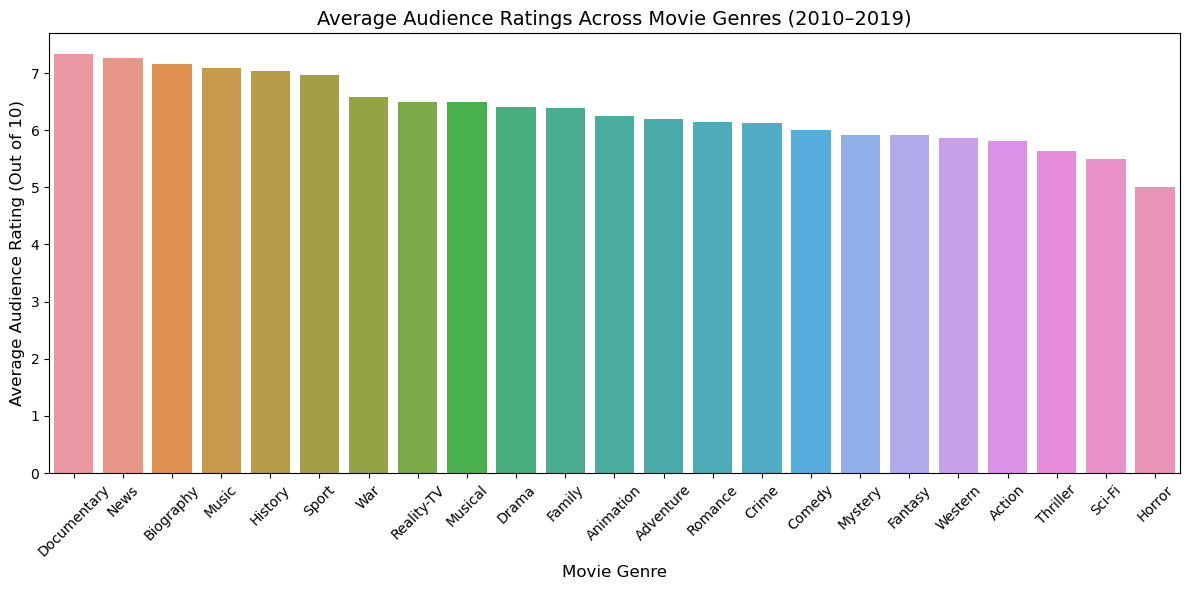

In [30]:

# Visualize average ratings by genre

plt.figure(figsize=(12, 6))

sns.barplot(
    data=genre_ratings.sort_values(
        'average_rating',
        ascending=False
    ),
    x='genre',
    y='average_rating'
)

plt.title(
    'Average Audience Ratings Across Movie Genres (2010–2019)',
    fontsize=14
)

plt.xlabel('Movie Genre', fontsize=12)
plt.ylabel('Average Audience Rating (Out of 10)', fontsize=12)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


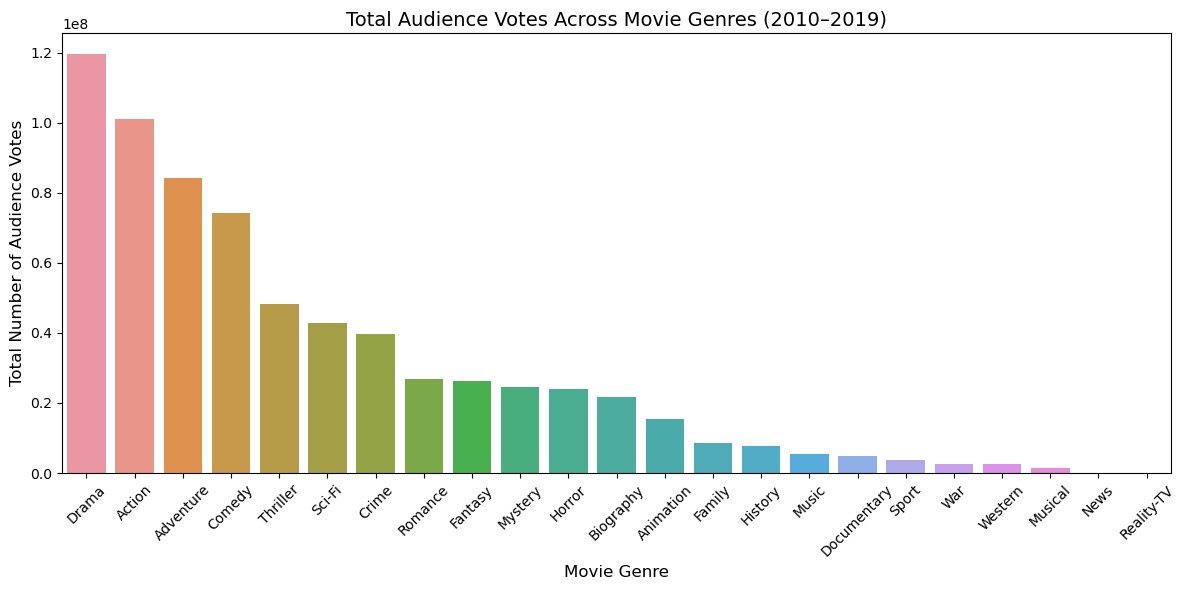

In [31]:

# Visualize total audience votes by genre

plt.figure(figsize=(12, 6))

sns.barplot(
    data=genre_ratings.sort_values(
        'total_votes',
        ascending=False
    ),
    x='genre',
    y='total_votes'
)

plt.title(
    'Total Audience Votes Across Movie Genres (2010–2019)',
    fontsize=14
)

plt.xlabel('Movie Genre', fontsize=12)
plt.ylabel('Total Number of Audience Votes', fontsize=12)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [32]:

# Check missing values in movie_basics

missing_movies = pd.read_sql_query("""
    SELECT
        COUNT(*) AS total_records,
        SUM(CASE WHEN primary_title IS NULL THEN 1 ELSE 0 END)
            AS missing_titles,
        SUM(CASE WHEN start_year IS NULL THEN 1 ELSE 0 END)
            AS missing_years,
        SUM(CASE WHEN genres IS NULL THEN 1 ELSE 0 END)
            AS missing_genres,
        SUM(CASE WHEN runtime_minutes IS NULL THEN 1 ELSE 0 END)
            AS missing_runtime
    FROM movie_basics
""", conn4)

missing_movies


,total_records,missing_titles,missing_years,missing_genres,missing_runtime
0,146144,0,0,5408,31739


In [33]:

# Check missing values in movie_ratings

missing_ratings = pd.read_sql_query("""
    SELECT
        COUNT(*) AS total_records,
        SUM(CASE WHEN averagerating IS NULL THEN 1 ELSE 0 END)
            AS missing_ratings,
        SUM(CASE WHEN numvotes IS NULL THEN 1 ELSE 0 END)
            AS missing_votes
    FROM movie_ratings
""", conn4)

missing_ratings


,total_records,missing_ratings,missing_votes
0,73856,0,0


In [34]:

# Identify duplicate movie records

duplicate_movies = pd.read_sql_query("""
    SELECT
        movie_id,
        COUNT(*) AS occurrences
    FROM movie_basics
    GROUP BY movie_id
    HAVING COUNT(*) > 1
""", conn4)

duplicate_movies


,movie_id,occurrences


In [35]:

# Close database connection
conn4.close()

print("Database connection closed successfully!")


Database connection closed successfully!
